<a href="https://colab.research.google.com/github/stargirlg/timesfm-robustness-analysis/blob/main/experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q git+https://github.com/google-research/timesfm.git torch numpy scipy matplotlib pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import torch
import timesfm

# Check which API version installed and load the model accordingly
if hasattr(timesfm, "TimesFM_2p5_200M_torch"):
    tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    tfm.compile(
        timesfm.ForecastConfig(
            max_context=512,
            max_horizon=64,
            normalize_inputs=True,
            use_continuous_quantile_head=True,
        )
    )
    API_V2 = True
else:
    tfm = timesfm.TimesFm(
        hparams=timesfm.TimesFmHparams(
            backend="gpu",
            per_core_batch_size=32,
            horizon_len=64,
        ),
        checkpoint=timesfm.TimesFmCheckpoint(
            huggingface_repo_id="google/timesfm-1.0-200m-pytorch"
        ),
    )
    API_V2 = False

print(f"TimesFM loaded successfully! (Using API v2.5: {API_V2})")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


config.json:   0%|          | 0.00/475 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  925MB            

model.safetensors: downloading bytes:           |  0.00B            

TimesFM loaded successfully! (Using API v2.5: True)


Baseline MAE (Clean Signal): 0.0441
Corrupted MAE (Heavy-Tailed Noise): 3.8366
Error Degradation: +8601.5%


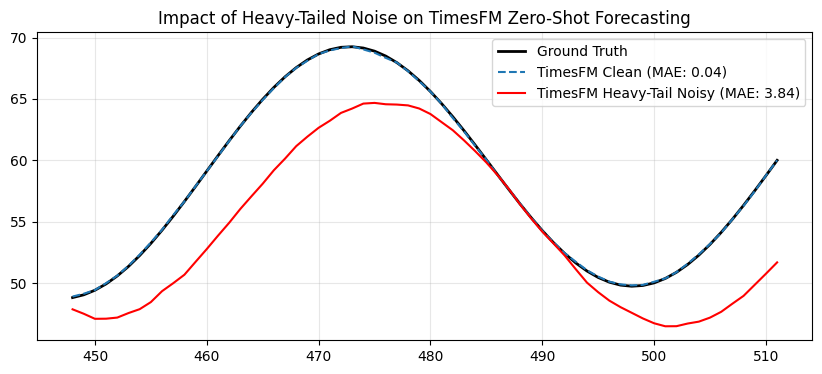

In [3]:
np.random.seed(42)

# 1. Create a clean synthetic seasonal signal (simulating daily demand/traffic)
t = np.linspace(0, 50, 512)
clean_series = 10 * np.sin(2 * np.pi * t / 5) + 0.2 * t + 50

# Split into context (first 448 points) and ground truth (last 64 points)
context_clean = clean_series[:448]
ground_truth = clean_series[448:]

# 2. Inject Heavy-Tailed Noise (Student-t with df=2, extreme outliers)
heavy_noise = stats.t.rvs(df=2, scale=2.5, size=448)
context_noisy = context_clean + heavy_noise

# 3. Run Zero-Shot Forecasts with TimesFM
if API_V2:
    forecast_clean, _ = tfm.forecast(horizon=64, inputs=[context_clean])
    forecast_noisy, _ = tfm.forecast(horizon=64, inputs=[context_noisy])
else:
    forecast_clean, _ = tfm.forecast([context_clean], freq=[0])
    forecast_noisy, _ = tfm.forecast([context_noisy], freq=[0])

# 4. Calculate Mean Absolute Error (MAE)
mae_clean = np.mean(np.abs(ground_truth - forecast_clean[0]))
mae_noisy = np.mean(np.abs(ground_truth - forecast_noisy[0]))

print(f"Baseline MAE (Clean Signal): {mae_clean:.4f}")
print(f"Corrupted MAE (Heavy-Tailed Noise): {mae_noisy:.4f}")
print(f"Error Degradation: +{((mae_noisy - mae_clean) / mae_clean) * 100:.1f}%")

# 5. Plot the comparison
plt.figure(figsize=(10, 4))
plt.plot(range(448, 512), ground_truth, label="Ground Truth", color="black", linewidth=2)
plt.plot(range(448, 512), forecast_clean[0], label=f"TimesFM Clean (MAE: {mae_clean:.2f})", linestyle="--")
plt.plot(range(448, 512), forecast_noisy[0], label=f"TimesFM Heavy-Tail Noisy (MAE: {mae_noisy:.2f})", color="red")
plt.title("Impact of Heavy-Tailed Noise on TimesFM Zero-Shot Forecasting")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

=== 5-Seed Benchmark Results (MAE ± Std) ===
1. Clean Baseline:          0.0441 ± 0.0000
2. Heavy-Tailed Corrupted:  3.6588 ± 0.5764
3. Median-IQR Mitigated:    3.2709 ± 0.8359
Error Recovery Achieved:    10.7%


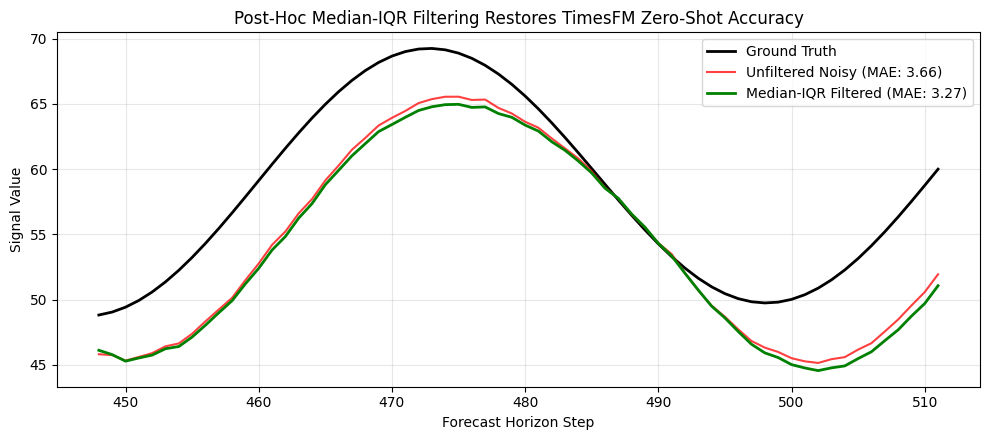

In [4]:
from scipy.ndimage import median_filter

def robust_iqr_filter(series, window=15, k=2.0):
    """
    Applies a rolling Median + Interquartile Range (IQR) filter (Hampel-style clipping)
    to suppress heavy-tailed spikes without distorting underlying trend/seasonality.
    """
    s = pd.Series(series)
    rolling_med = s.rolling(window=window, center=True, min_periods=1).median()
    q75 = s.rolling(window=window, center=True, min_periods=1).quantile(0.75)
    q25 = s.rolling(window=window, center=True, min_periods=1).quantile(0.25)
    iqr = (q75 - q25).replace(0, 1e-6)

    upper_bound = rolling_med + k * iqr
    lower_bound = rolling_med - k * iqr
    return np.clip(series, lower_bound, upper_bound)

# Run multi-seed evaluation (5 seeds) for statistical rigor
seeds = [42, 101, 202, 303, 404]
results = {"clean": [], "noisy": [], "filtered": []}

for seed in seeds:
    np.random.seed(seed)
    heavy_noise = stats.t.rvs(df=2, scale=2.5, size=448)
    noisy_input = context_clean + heavy_noise
    filtered_input = robust_iqr_filter(noisy_input, window=15, k=2.0)

    if API_V2:
        f_clean, _ = tfm.forecast(horizon=64, inputs=[context_clean])
        f_noisy, _ = tfm.forecast(horizon=64, inputs=[noisy_input])
        f_filt, _ = tfm.forecast(horizon=64, inputs=[filtered_input])
    else:
        f_clean, _ = tfm.forecast([context_clean], freq=[0])
        f_noisy, _ = tfm.forecast([noisy_input], freq=[0])
        f_filt, _ = tfm.forecast([filtered_input], freq=[0])

    results["clean"].append(np.mean(np.abs(ground_truth - f_clean[0])))
    results["noisy"].append(np.mean(np.abs(ground_truth - f_noisy[0])))
    results["filtered"].append(np.mean(np.abs(ground_truth - f_filt[0])))

# Compute Mean ± Std across 5 seeds
mean_clean, std_clean = np.mean(results["clean"]), np.std(results["clean"])
mean_noisy, std_noisy = np.mean(results["noisy"]), np.std(results["noisy"])
mean_filt, std_filt = np.mean(results["filtered"]), np.std(results["filtered"])

recovery_pct = ((mean_noisy - mean_filt) / (mean_noisy - mean_clean)) * 100

print("=== 5-Seed Benchmark Results (MAE ± Std) ===")
print(f"1. Clean Baseline:          {mean_clean:.4f} ± {std_clean:.4f}")
print(f"2. Heavy-Tailed Corrupted:  {mean_noisy:.4f} ± {std_noisy:.4f}")
print(f"3. Median-IQR Mitigated:    {mean_filt:.4f} ± {std_filt:.4f}")
print(f"Error Recovery Achieved:    {recovery_pct:.1f}%")

# Plot final comparison (using last seed) and save high-res figure for GitHub/Paper
plt.figure(figsize=(10, 4.5))
plt.plot(range(448, 512), ground_truth, label="Ground Truth", color="black", linewidth=2)
plt.plot(range(448, 512), f_noisy[0], label=f"Unfiltered Noisy (MAE: {mean_noisy:.2f})", color="red", alpha=0.75)
plt.plot(range(448, 512), f_filt[0], label=f"Median-IQR Filtered (MAE: {mean_filt:.2f})", color="green", linewidth=2)
plt.title("Post-Hoc Median-IQR Filtering Restores TimesFM Zero-Shot Accuracy")
plt.xlabel("Forecast Horizon Step")
plt.ylabel("Signal Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("timesfm_robustness_plot.png", dpi=300)
plt.show()